# Data Overview

A quick, non-technical look at the creativity ratings before running the
full psychometric analysis: how much data there is, how it is
distributed across actions and raters, a rough sense of how much raters
agree with each other, and how well-connected the rater-action design
currently is.

This notebook reads the preprocessed data produced by
`00_data_loading_preprocessing.ipynb` (`data/processed/ratings_long_clean.csv`).
It does not repeat or replace the formal reliability analysis in
`01_creativity_ratings_python.ipynb` / `01_creativity_ratings_R.qmd` — the
agreement figure here is a single quick estimate, not the fuller
subset/uncertainty treatment done there. The purpose of this notebook is
to inform decisions about future data collection: whether more ratings
are needed, and if so, from which raters on which actions.

## 1. Load the preprocessed data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import krippendorff

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

PROJECT_ROOT = Path("..").resolve()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(DATA_PROCESSED / "ratings_long_clean.csv")
df["action_id"] = df["action_id"].astype(str)
df["rater_id"] = df["rater_id"].astype(str)

print(f"Loaded {len(df)} ratings.")
df.head()

Loaded 7495 ratings.


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,urst3254,0786bb62-2032-444b-ac1f-59fa165dbb71,1.0,2.0,2.0,2026-03-11 11:50:29.717,1,1,5
1,anma2416,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,2.0,4.0,1.0,2025-11-18 12:26:15.275,2,2,708
2,anma2416,2bdc8133-ac12-45f1-9104-882873efa7bf,3.0,4.0,2.0,2025-10-15 13:35:18.000,3,3,17
3,azne2115,938d2c93-5e6f-442e-ba7c-f92c53080a42,5.0,5.0,5.0,2026-05-05 15:58:08.508,5,5,6
4,urst3254,4fe7a32b-09ce-466b-9772-494ed03ea493,6.0,7.0,7.0,2026-04-08 13:56:06.665,6,6,403


## 2. How much data do we have

Total number of ratings, and how many distinct actions and raters they
cover.

In [2]:
n_ratings = len(df)
n_actions = df["action_id"].nunique()
n_raters = df["rater_id"].nunique()

print(f"Total ratings:   {n_ratings}")
print(f"Distinct actions: {n_actions}")
print(f"Distinct raters:  {n_raters}")
print(f"Average ratings per action: {n_ratings / n_actions:.2f}")
print(f"Average ratings per rater:  {n_ratings / n_raters:.1f}")

Total ratings:   7495
Distinct actions: 3668
Distinct raters:  16
Average ratings per action: 2.04
Average ratings per rater:  468.4


## 3. Distribution of the number of ratings

Some actions have only one rating and contribute no within-action
agreement information; some raters have rated far more actions than
others. Both matter for how much we can trust the eventual reliability
estimates.

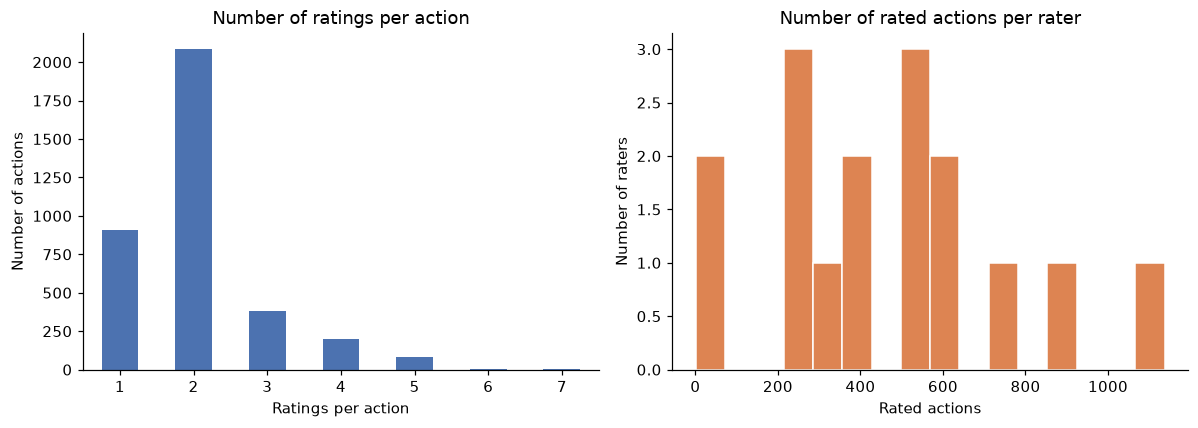

Ratings per action:
count    3668.000000
mean        2.043348
std         0.903302
min         1.000000
25%         2.000000
50%         2.000000
75%         2.000000
max         7.000000
Name: n_ratings, dtype: float64

Share of actions with exactly 1 rating: 24.8%
Share of actions with exactly 2 ratings: 56.8%

Ratings per rater:
rater_id
elmi2612        1
chra1754       50
clpe1410      254
nayü2116      259
bebe58        264
CNNW38        351
sude306       383
azne2115      400
kauw2915      520
chra3054      522
ZVNQ65        534
urst3254      594
hüan04        633
anma2416      720
nedu1581      873
mana12312    1137
Name: n_actions_rated, dtype: int64


In [3]:
ratings_per_action = df.groupby("action_id").size().rename("n_ratings")
ratings_per_rater = df.groupby("rater_id").size().rename("n_actions_rated")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ratings_per_action.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Number of ratings per action")
axes[0].set_xlabel("Ratings per action")
axes[0].set_ylabel("Number of actions")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

axes[1].hist(ratings_per_rater.values, bins=min(20, n_raters), color="#DD8452", edgecolor="white")
axes[1].set_title("Number of rated actions per rater")
axes[1].set_xlabel("Rated actions")
axes[1].set_ylabel("Number of raters")
fig.tight_layout()
plt.show()

print("Ratings per action:")
print(ratings_per_action.describe())
print(f"\nShare of actions with exactly 1 rating: {(ratings_per_action == 1).mean():.1%}")
print(f"Share of actions with exactly 2 ratings: {(ratings_per_action == 2).mean():.1%}")

print("\nRatings per rater:")
print(ratings_per_rater.sort_values())

## 4. Rough agreement across raters

A single overall Krippendorff's alpha (interval level), computed
directly on the full incomplete rater-action design — the coefficient
handles the unequal, incomplete overlap between raters natively, so no
subsetting is needed for a quick read. This is a rough, one-number
summary; the full analysis notebooks compute alpha with uncertainty
intervals and on relevant subsets of the data.

In [4]:
reliability_matrix = (
    df.pivot_table(index="rater_id", columns="action_id", values="rating_numeric")
    .to_numpy()
)
alpha = krippendorff.alpha(reliability_data=reliability_matrix, level_of_measurement="interval")
print(f"Krippendorff's alpha (interval, rough overall estimate): {alpha:.3f}")

pairable_actions = (ratings_per_action >= 2).sum()
print(f"Actions with >=2 ratings (contributing to this estimate): {pairable_actions} "
      f"of {n_actions} ({pairable_actions / n_actions:.1%})")

Krippendorff's alpha (interval, rough overall estimate): 0.422
Actions with >=2 ratings (contributing to this estimate): 2759 of 3668 (75.2%)


## 5. Connectivity of the rater-action design

Rater severity/leniency can only be told apart from true differences
between actions if raters are linked, directly or indirectly, through
shared actions. We build the rater-action bipartite graph and check how
connected it currently is, and how much overlap each pair of raters has.

In [5]:
B = nx.Graph()
B.add_nodes_from(df["action_id"].unique(), bipartite="action")
B.add_nodes_from(("R::" + df["rater_id"]).unique(), bipartite="rater")
B.add_edges_from(zip(df["action_id"], "R::" + df["rater_id"]))

components = sorted(nx.connected_components(B), key=len, reverse=True)
comp_summary = []
for i, comp in enumerate(components):
    action_nodes = [n for n in comp if not str(n).startswith("R::")]
    rater_nodes = [str(n)[3:] for n in comp if str(n).startswith("R::")]
    comp_summary.append({
        "component_id": i, "n_actions": len(action_nodes),
        "n_raters": len(rater_nodes), "raters": ", ".join(sorted(rater_nodes)),
    })
comp_summary_df = pd.DataFrame(comp_summary)
print(f"Number of connected components: {len(components)}")
comp_summary_df

Number of connected components: 2


,component_id,n_actions,n_raters,raters
0,0,3667,15,"CNNW38, ZVNQ65, anma2416, azne2115, bebe58, ch..."
1,1,1,1,elmi2612


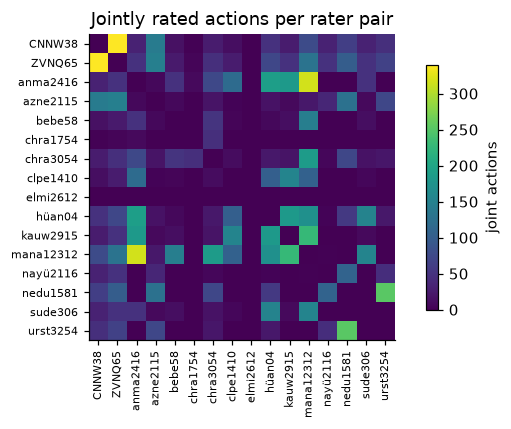

Best-connected-partner overlap per rater (lower = more isolated):
elmi2612       0
chra1754      46
nayü2116     108
bebe58       145
azne2115     147
sude306      154
clpe1410     154
chra3054     187
hüan04       190
kauw2915     228
urst3254     253
nedu1581     253
anma2416     317
mana12312    317
ZVNQ65       340
CNNW38       340
Name: best_partner_overlap, dtype: int64


In [6]:
rater_ids_sorted = sorted(df["rater_id"].unique())
n = len(rater_ids_sorted)
rater_idx = {r: i for i, r in enumerate(rater_ids_sorted)}

overlap = np.zeros((n, n), dtype=int)
for raters_for_action in df.groupby("action_id")["rater_id"].apply(list):
    idxs = sorted(set(rater_idx[r] for r in raters_for_action))
    for a in range(len(idxs)):
        for b in range(a + 1, len(idxs)):
            overlap[idxs[a], idxs[b]] += 1
            overlap[idxs[b], idxs[a]] += 1

overlap_df = pd.DataFrame(overlap, index=rater_ids_sorted, columns=rater_ids_sorted)

# For each rater: overlap with their single best-connected partner.
best_partner_overlap = pd.Series(
    {r: overlap_df.loc[r].drop(r).max() for r in rater_ids_sorted},
    name="best_partner_overlap",
).sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(overlap, cmap="viridis")
ax.set_title("Jointly rated actions per rater pair")
ax.set_xticks(range(n)); ax.set_xticklabels(rater_ids_sorted, rotation=90, fontsize=7)
ax.set_yticks(range(n)); ax.set_yticklabels(rater_ids_sorted, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="joint actions")
fig.tight_layout()
plt.show()

print("Best-connected-partner overlap per rater (lower = more isolated):")
print(best_partner_overlap)

## 6. Recommendations for future rater-action assignment

Grounded in the numbers computed above. A commonly used rule of thumb
for this kind of design is at least 15-20 shared actions between a rater
and at least one well-connected "bridge" rater, so that relative rater
strictness can be calibrated; actions rated by (nearly) all raters
("anchor actions") further stabilize this.

In [7]:
OVERLAP_TARGET = 15

recommendations = []

if len(components) > 1:
    recommendations.append(
        f"The rater-action graph currently has {len(components)} disconnected "
        "components. Raters in different components cannot be compared on the "
        "same severity scale at all. Priority: assign at least a few shared "
        "actions between the largest component and each of the others."
    )

low_overlap_raters = best_partner_overlap[best_partner_overlap < OVERLAP_TARGET]
if len(low_overlap_raters) > 0:
    recommendations.append(
        f"{len(low_overlap_raters)} of {n_raters} raters have fewer than "
        f"{OVERLAP_TARGET} shared actions with their best-connected partner: "
        f"{', '.join(low_overlap_raters.index)}. Assigning more overlapping "
        "actions between these raters and the rest of the pool would improve "
        "how reliably their severity can be calibrated."
    )

single_rating_share = (ratings_per_action == 1).mean()
if single_rating_share > 0.1:
    recommendations.append(
        f"{single_rating_share:.0%} of actions currently have only one rating "
        "and contribute no within-action agreement information. Adding a "
        "second rater to a sample of these would materially improve the "
        "precision of the overall agreement estimate."
    )

thin_raters = ratings_per_rater[ratings_per_rater < ratings_per_rater.median() / 2]
if len(thin_raters) > 0:
    recommendations.append(
        f"{len(thin_raters)} raters have rated notably fewer actions than the "
        f"median rater ({ratings_per_rater.median():.0f}): "
        f"{', '.join(thin_raters.index)}. More ratings from these raters would "
        "make their individual severity/leniency estimates more precise."
    )

if not recommendations:
    recommendations.append(
        "No major coverage gaps found by these quick checks: the design is a "
        "single connected component, no rater falls far short of the overlap "
        "target, and only a small share of actions have a single rating."
    )

for i, rec in enumerate(recommendations, start=1):
    print(f"{i}. {rec}")

1. The rater-action graph currently has 2 disconnected components. Raters in different components cannot be compared on the same severity scale at all. Priority: assign at least a few shared actions between the largest component and each of the others.
2. 1 of 16 raters have fewer than 15 shared actions with their best-connected partner: elmi2612. Assigning more overlapping actions between these raters and the rest of the pool would improve how reliably their severity can be calibrated.
3. 25% of actions currently have only one rating and contribute no within-action agreement information. Adding a second rater to a sample of these would materially improve the precision of the overall agreement estimate.
4. 2 raters have rated notably fewer actions than the median rater (460): chra1754, elmi2612. More ratings from these raters would make their individual severity/leniency estimates more precise.
